In [1]:
!pip install catboost xgboost lightgbm gradio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [3]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
df.shape

(5110, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [8]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.reset_index(drop=True,inplace=True)

In [12]:
df.isnull().sum().sort_values(ascending=False).head()

,0
bmi,201
id,0
age,0
gender,0
hypertension,0


In [13]:
from sklearn.impute import SimpleImputer
imputer_bmi = SimpleImputer(strategy='median')
df[['bmi']] = imputer_bmi.fit_transform(df[['bmi']])

In [14]:
(df[['bmi']].isnull().sum())

,0
bmi,0


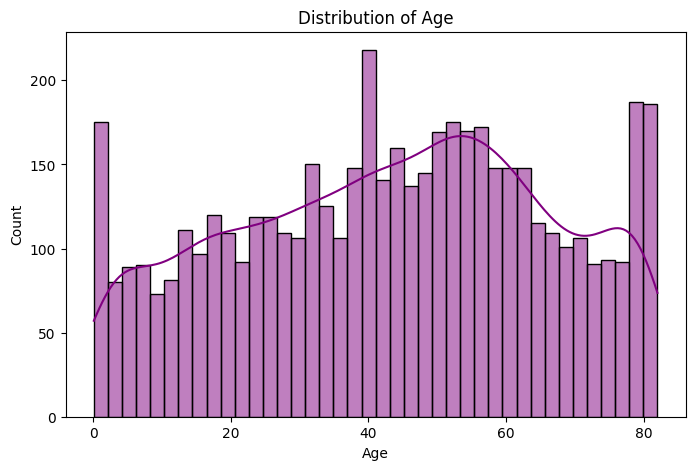

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=40, kde=True, color='purple')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_6744/6836335.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stroke', y='age', data=df, palette='Set2')


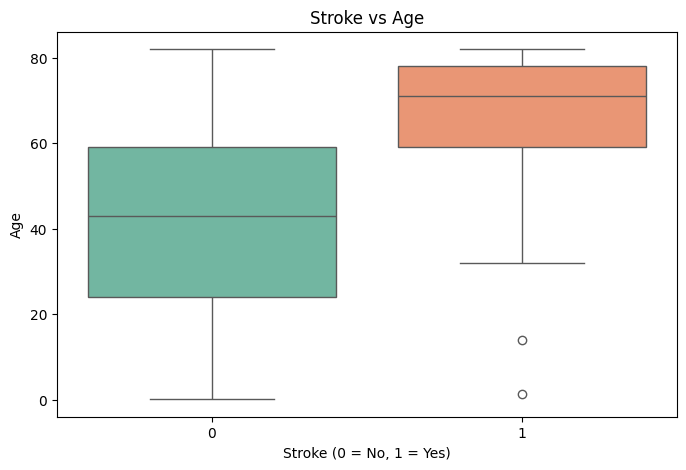

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='stroke', y='age', data=df, palette='Set2')
plt.title('Stroke vs Age')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.show()

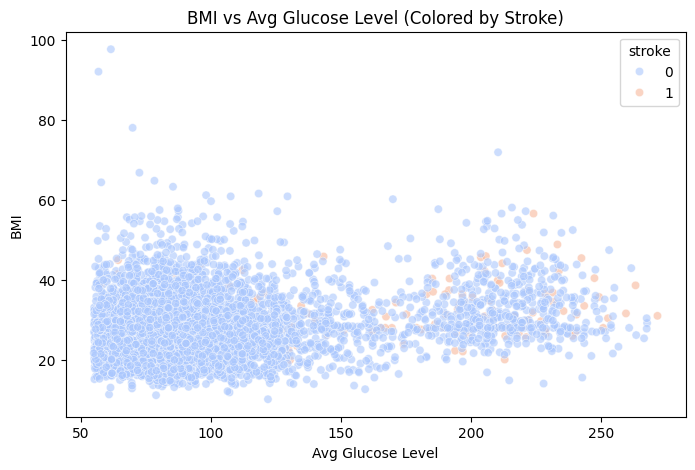

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df, hue='stroke', alpha=0.6, palette='coolwarm')
plt.title('BMI vs Avg Glucose Level (Colored by Stroke)')
plt.xlabel('Avg Glucose Level')
plt.ylabel('BMI')
plt.show()

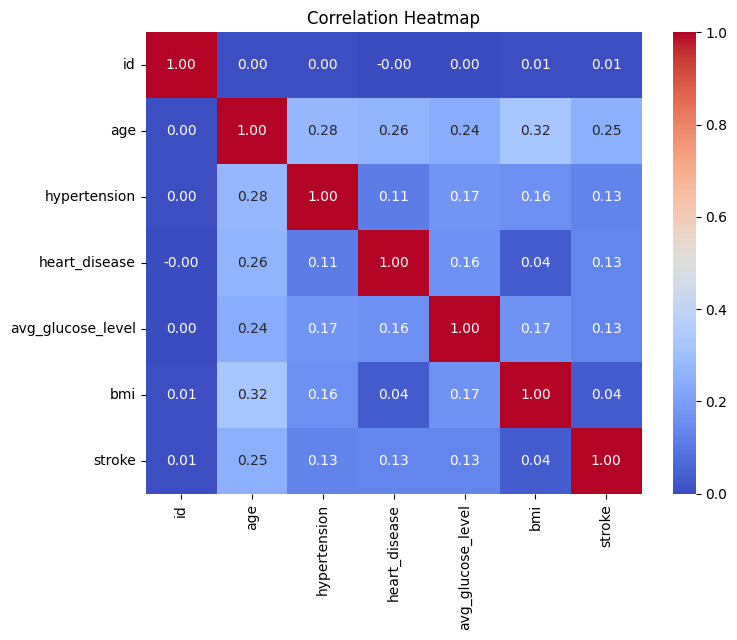

In [18]:
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'], drop_first=True)

print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)

Shape before encoding: (5110, 12)
Shape after encoding: (5110, 18)


In [20]:
X = df_encoded.drop(columns=['stroke', 'id'], errors='ignore')
y = df_encoded['stroke']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5110, 16)
y shape: (5110,)


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (2555, 16)
X_test shape: (2555, 16)


In [22]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled X_train:", round(X_train_scaled.mean(), 5))
print("Std of scaled X_train:", round(X_train_scaled.std(), 5))

Mean of scaled X_train: -0.0
Std of scaled X_train: 0.96825


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [24]:
model = LogisticRegression(class_weight={0: 1, 1: 5}, C=0.1, max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(C=0.1, class_weight={0: 1, 1: 5}, max_iter=1000)

In [25]:
y_pred = model.predict(X_test_scaled)

In [26]:
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.94      0.95      2426
           1       0.26      0.36      0.30       129

    accuracy                           0.92      2555
   macro avg       0.61      0.65      0.63      2555
weighted avg       0.93      0.92      0.92      2555



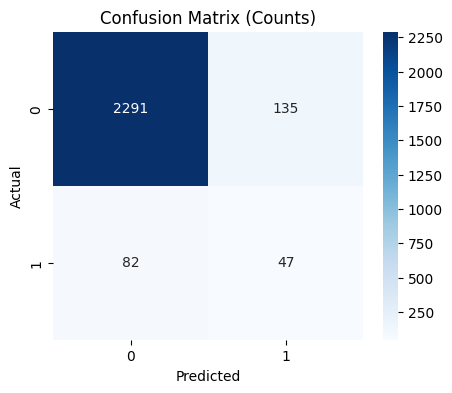

In [27]:
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Counts)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

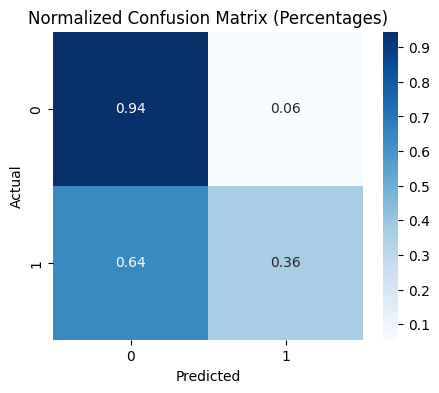

In [28]:
plt.figure(figsize=(5, 4))
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='0.2f', cmap='Blues')
plt.title('Normalized Confusion Matrix (Percentages)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [29]:
metrics_df = pd.DataFrame(
    [[accuracy_score(y_test, y_pred),
      precision_score(y_test, y_pred),
      recall_score(y_test, y_pred),
      f1_score(y_test, y_pred)]],
    index=['Logistic Regression'],
    columns=['Accuracy', 'Precision', 'Recall', 'F1-Score']
)

display(metrics_df)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.915068,0.258242,0.364341,0.302251


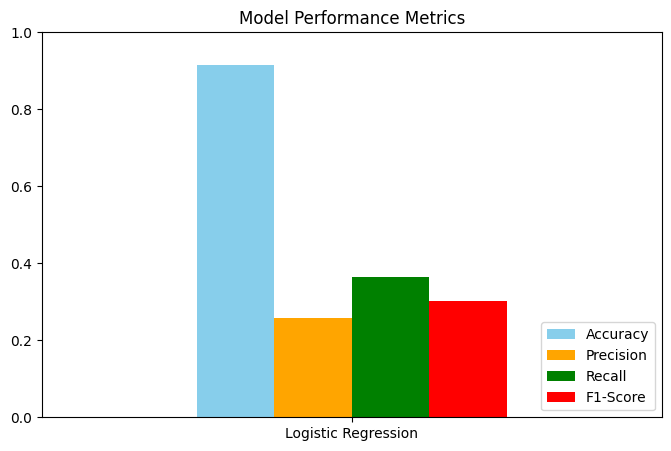

In [30]:
metrics_df.plot(kind='bar', figsize=(8, 5), color=['skyblue', 'orange', 'green', 'red'])
plt.title('Model Performance Metrics')
plt.ylim(0, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [31]:
results = []

# Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [32]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (4870, 16)  y_train_smote =  (4870,)


In [33]:
y_train_smote.value_counts()

,count
stroke,
0,2435
1,2435


In [34]:
# Logistic Regression Using Smote Over Sampling
model = LogisticRegression()
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Under Sampling

In [35]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (240, 16)  y_train_rus =  (240,)


In [36]:
y_train_rus.value_counts()

,count
stroke,
0,120
1,120


In [37]:
# Logistic Regression Using RandomOverSampler Under Sampling
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Class Weights

In [38]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [39]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight={0:1,1:10})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced Custom",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [40]:
np.unique(y_train)

array([0, 1])

In [41]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Normal Data,0.949902,1.000000,0.007752,0.015385
SMOTE Over Sampling,0.847358,0.138504,0.387597,0.204082
SMOTE Over Sampling,0.728767,0.138462,0.837209,0.237624
Class Weight Balanced,0.733072,0.134742,0.790698,0.230248
Class Weight Balanced Custom,0.841096,0.183066,0.620155,0.282686


In [42]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[2426    0]
 [ 128    1]]


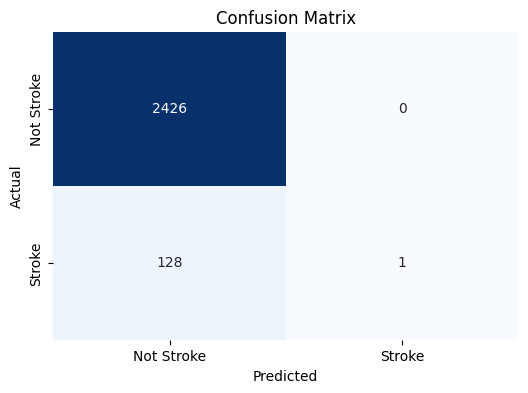


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       1.00      0.01      0.02       129

    accuracy                           0.95      2555
   macro avg       0.97      0.50      0.49      2555
weighted avg       0.95      0.95      0.93      2555

ROC-AUC: 0.8381008071473763


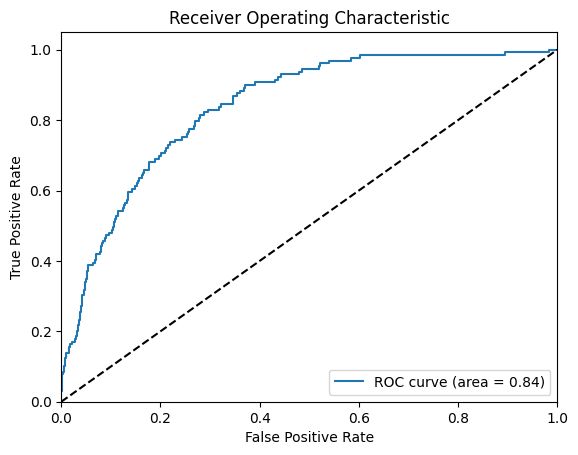

PR AUC: 0.24725101028464283


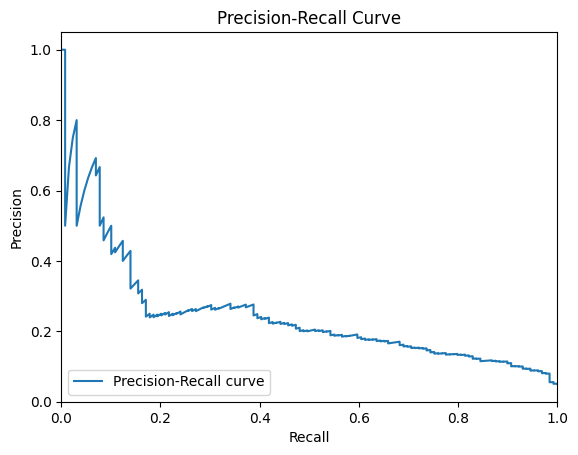

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
  8%|▊         | 1/13 [00:02<00:34,  2.85s/it]


Confusion Matrix:
 [[2410   16]
 [ 125    4]]


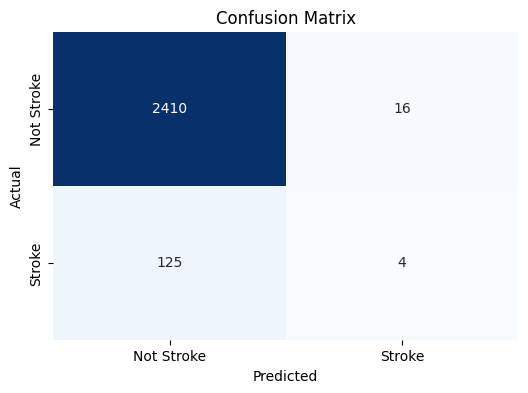


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.20      0.03      0.05       129

    accuracy                           0.94      2555
   macro avg       0.58      0.51      0.51      2555
weighted avg       0.91      0.94      0.93      2555

ROC-AUC: 0.6708366085750622


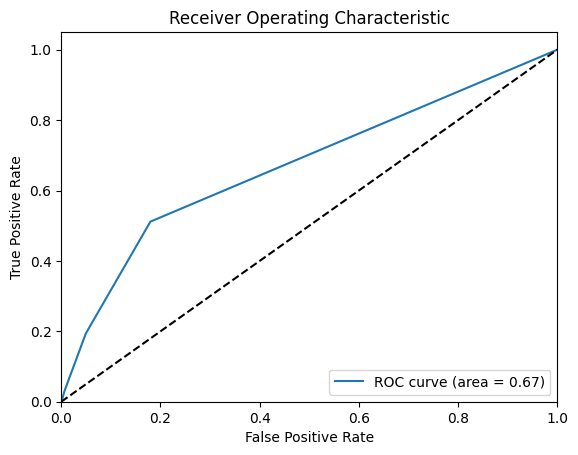

PR AUC: 0.1007127893022681


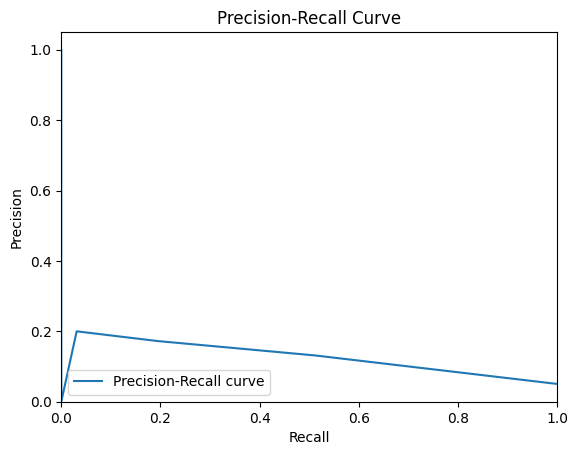

 15%|█▌        | 2/13 [00:04<00:21,  1.95s/it]


Confusion Matrix:
 [[2426    0]
 [ 129    0]]


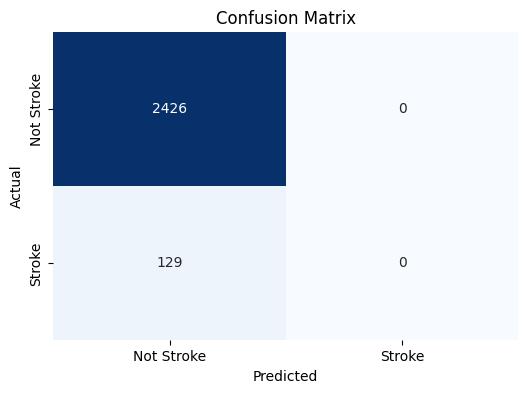


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.00      0.00      0.00       129

    accuracy                           0.95      2555
   macro avg       0.47      0.50      0.49      2555
weighted avg       0.90      0.95      0.92      2555

ROC-AUC: 0.35299756513736846


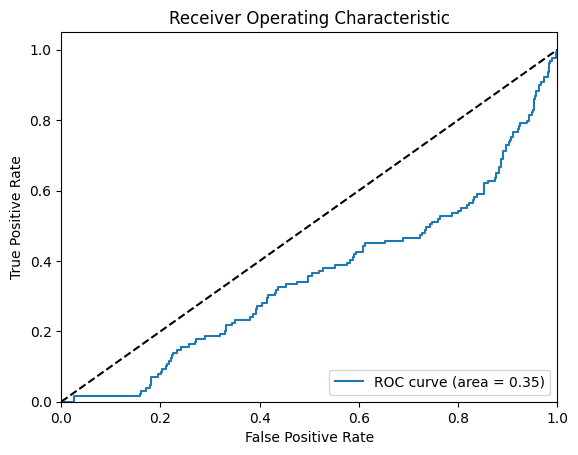

PR AUC: 0.03657738743426363


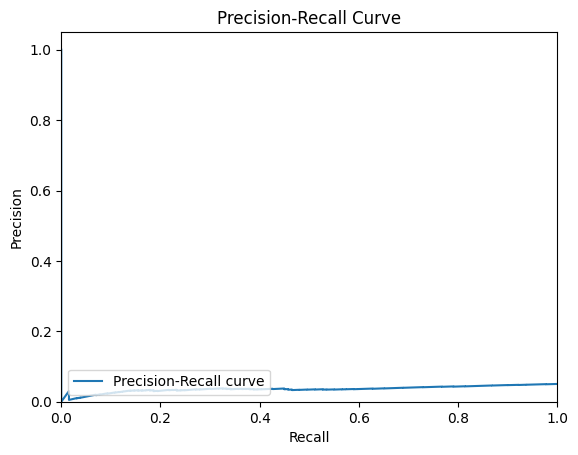

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:07<00:26,  2.65s/it]


Confusion Matrix:
 [[2313  113]
 [ 105   24]]


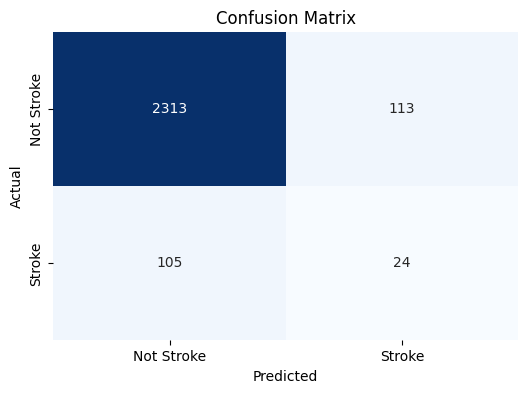


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.95      0.95      2426
      Stroke       0.18      0.19      0.18       129

    accuracy                           0.91      2555
   macro avg       0.57      0.57      0.57      2555
weighted avg       0.92      0.91      0.92      2555

ROC-AUC: 0.5697338906037308


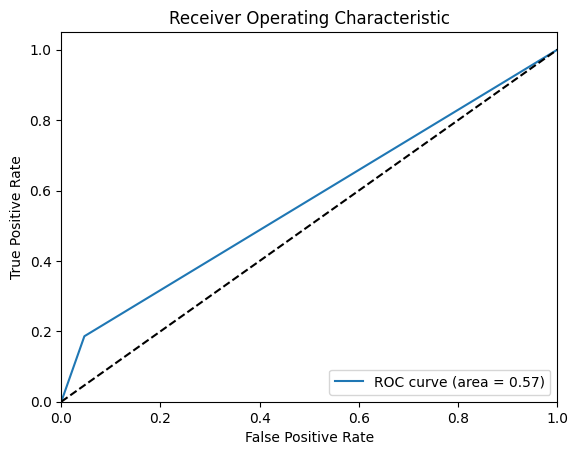

PR AUC: 0.07368798003920539


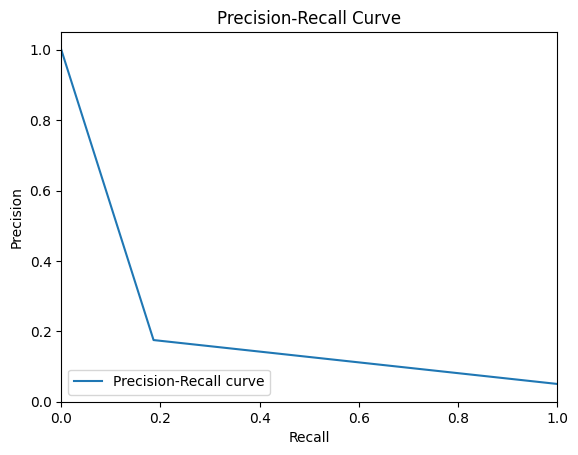

 31%|███       | 4/13 [00:08<00:18,  2.08s/it]


Confusion Matrix:
 [[ 798 1628]
 [   2  127]]


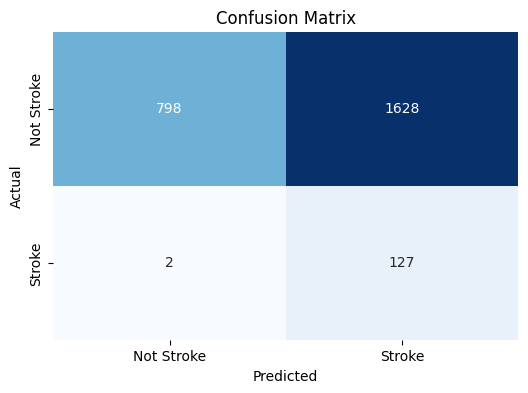


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.33      0.49      2426
      Stroke       0.07      0.98      0.13       129

    accuracy                           0.36      2555
   macro avg       0.53      0.66      0.31      2555
weighted avg       0.95      0.36      0.48      2555

ROC-AUC: 0.8126881266895454


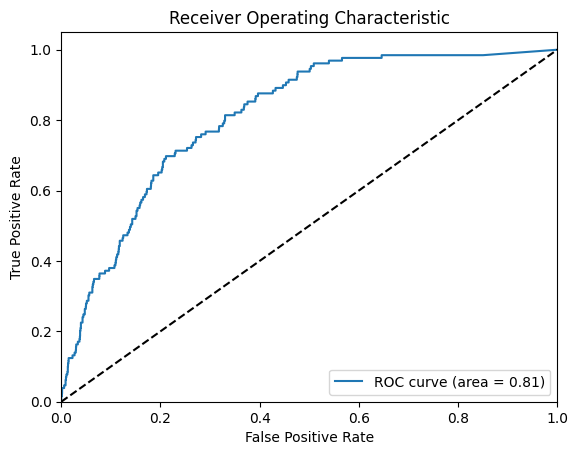

PR AUC: 0.1898109213924875


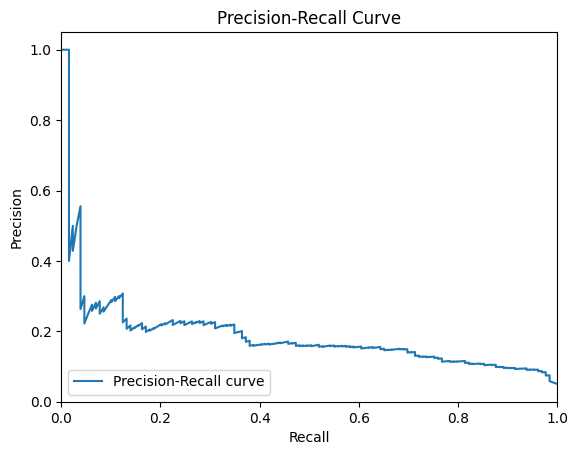

 38%|███▊      | 5/13 [00:09<00:13,  1.73s/it]


Confusion Matrix:
 [[2423    3]
 [ 128    1]]


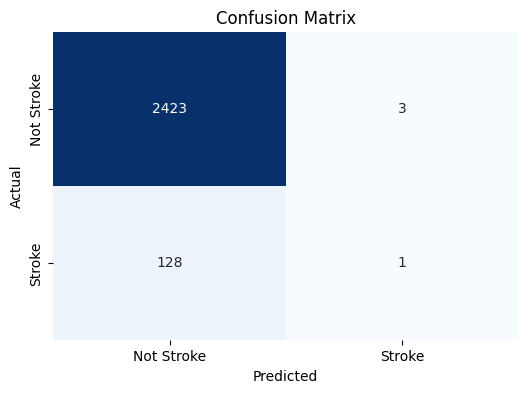


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.25      0.01      0.02       129

    accuracy                           0.95      2555
   macro avg       0.60      0.50      0.49      2555
weighted avg       0.91      0.95      0.93      2555

ROC-AUC: 0.7933849703151261


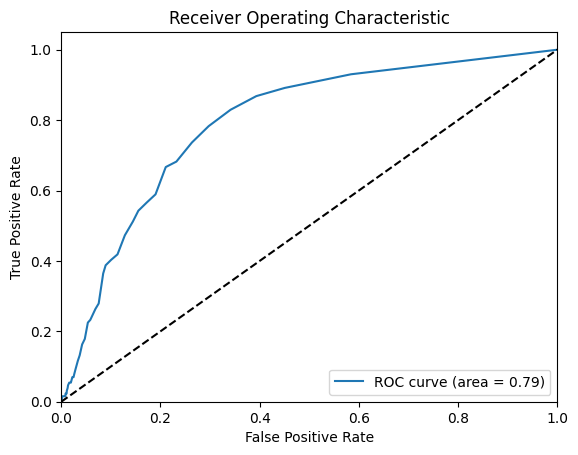

PR AUC: 0.14342742096278543


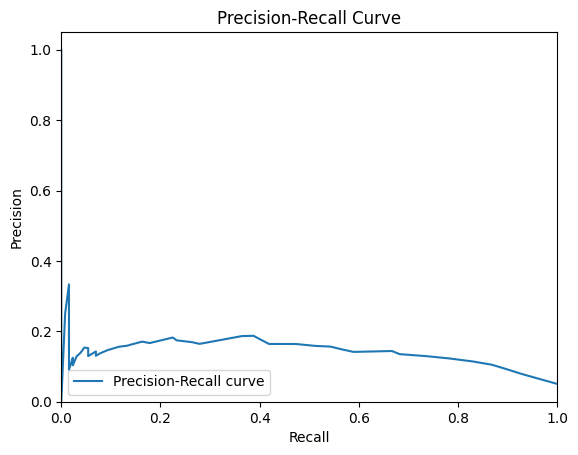

 46%|████▌     | 6/13 [00:12<00:13,  1.91s/it]


Confusion Matrix:
 [[2407   19]
 [ 124    5]]


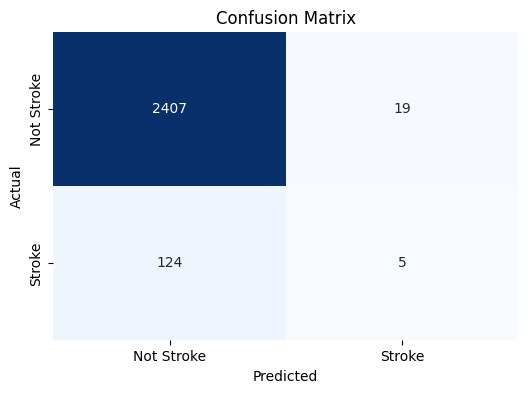


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.21      0.04      0.07       129

    accuracy                           0.94      2555
   macro avg       0.58      0.52      0.52      2555
weighted avg       0.91      0.94      0.93      2555

ROC-AUC: 0.7249691647973824


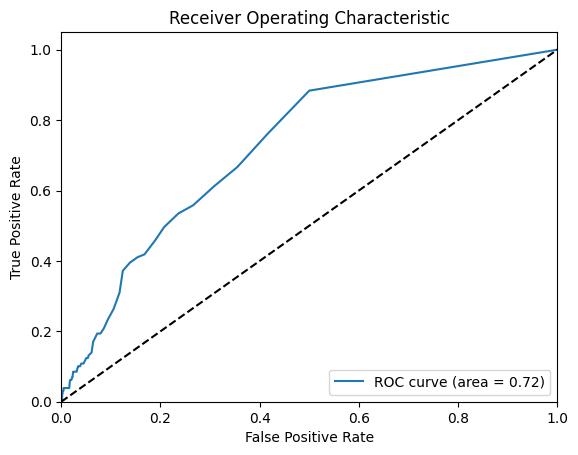

PR AUC: 0.11125609007883484


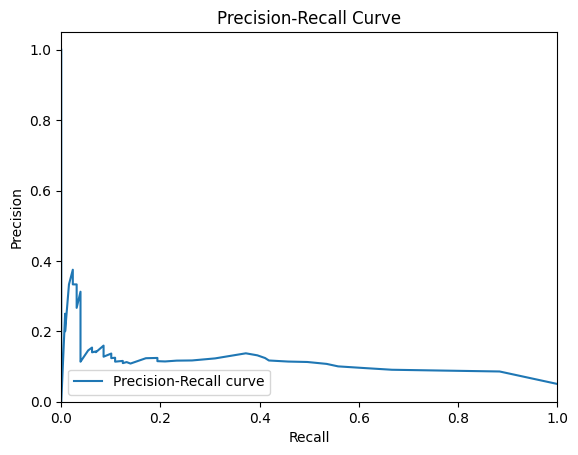

 54%|█████▍    | 7/13 [00:16<00:15,  2.57s/it]


Confusion Matrix:
 [[2426    0]
 [ 129    0]]


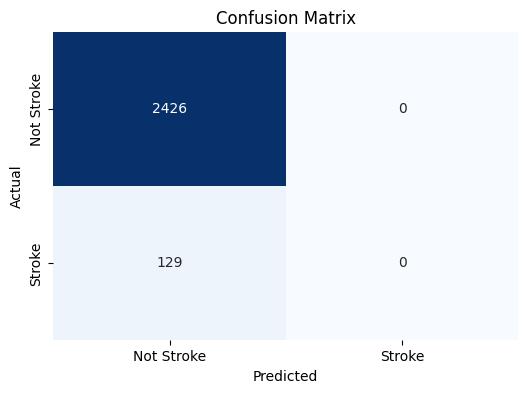


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.00      0.00      0.00       129

    accuracy                           0.95      2555
   macro avg       0.47      0.50      0.49      2555
weighted avg       0.90      0.95      0.92      2555

ROC-AUC: 0.8313282463237408


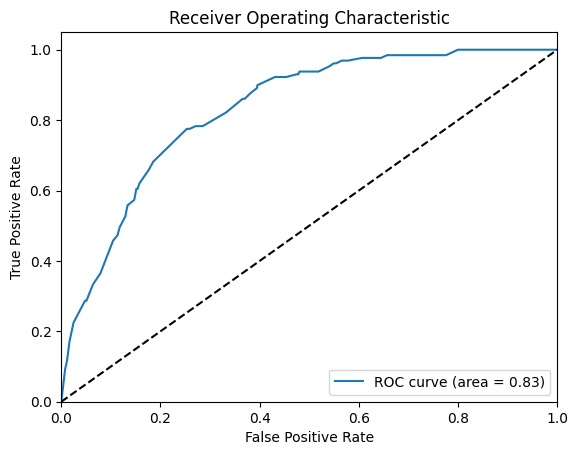

PR AUC: 0.2049559452392745


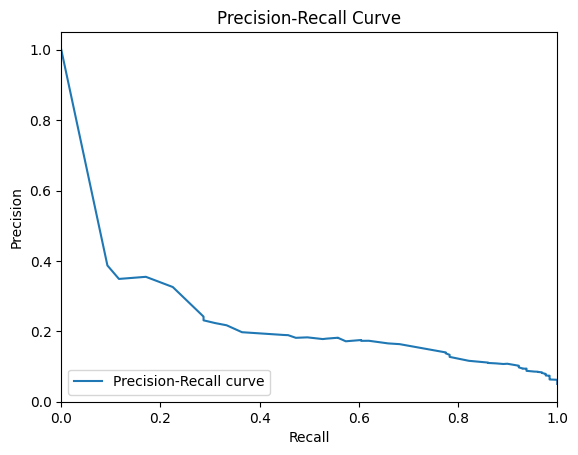

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:17<00:11,  2.30s/it]


Confusion Matrix:
 [[2421    5]
 [ 128    1]]


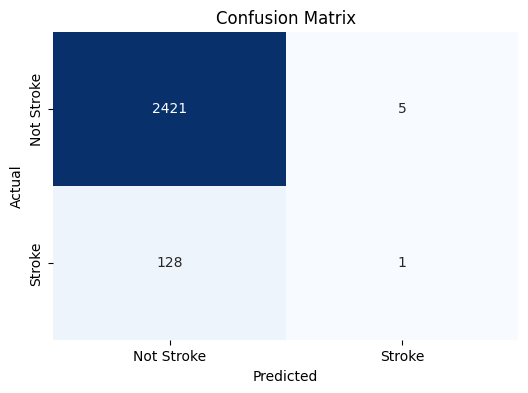


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.17      0.01      0.01       129

    accuracy                           0.95      2555
   macro avg       0.56      0.50      0.49      2555
weighted avg       0.91      0.95      0.92      2555

ROC-AUC: 0.8108012679179688


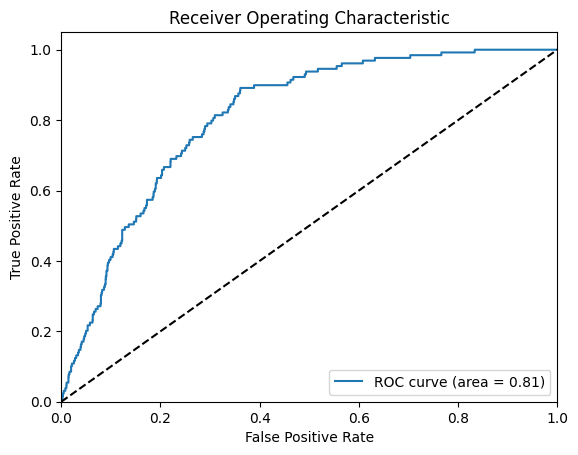

PR AUC: 0.1541323602870011


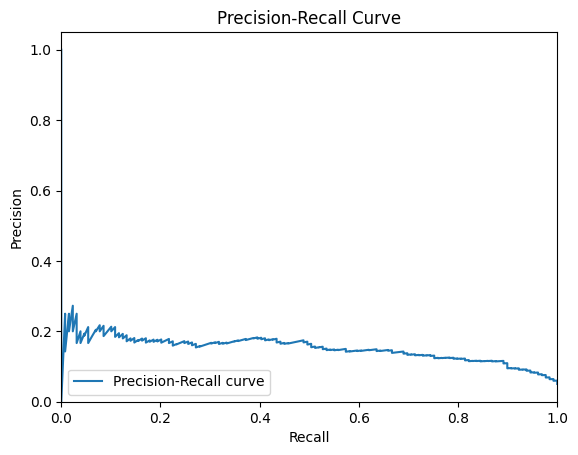

 69%|██████▉   | 9/13 [00:20<00:09,  2.35s/it]


Confusion Matrix:
 [[2414   12]
 [ 121    8]]


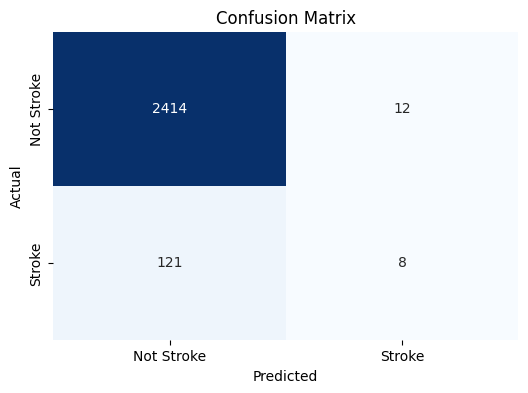


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.40      0.06      0.11       129

    accuracy                           0.95      2555
   macro avg       0.68      0.53      0.54      2555
weighted avg       0.92      0.95      0.93      2555

ROC-AUC: 0.8145797784977985


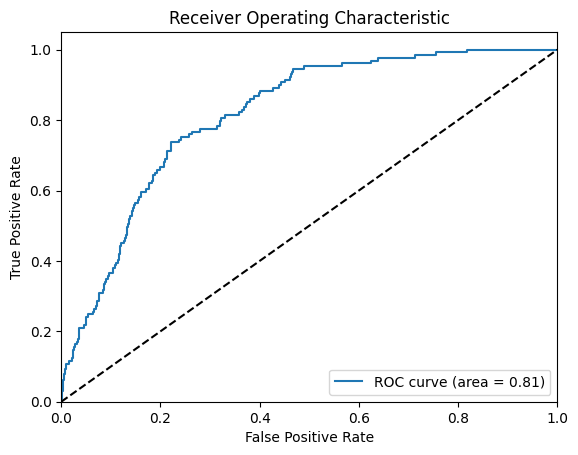

PR AUC: 0.1827237217744196


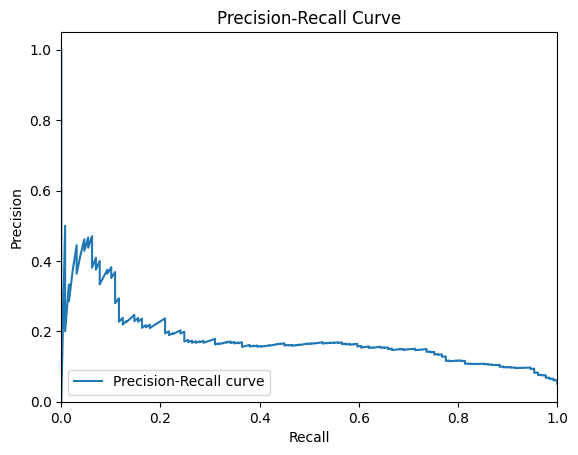

 77%|███████▋  | 10/13 [00:22<00:06,  2.27s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:46:12] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[2406   20]
 [ 120    9]]


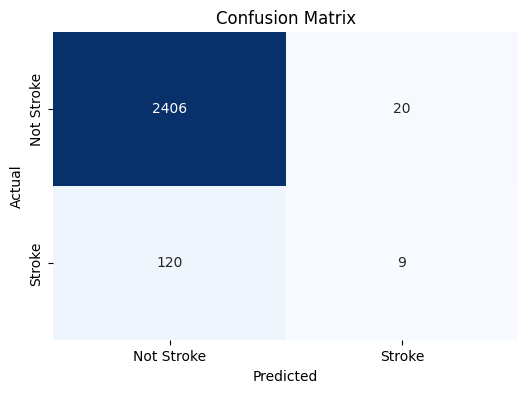


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.31      0.07      0.11       129

    accuracy                           0.95      2555
   macro avg       0.63      0.53      0.54      2555
weighted avg       0.92      0.95      0.93      2555

ROC-AUC: 0.8057829585178653


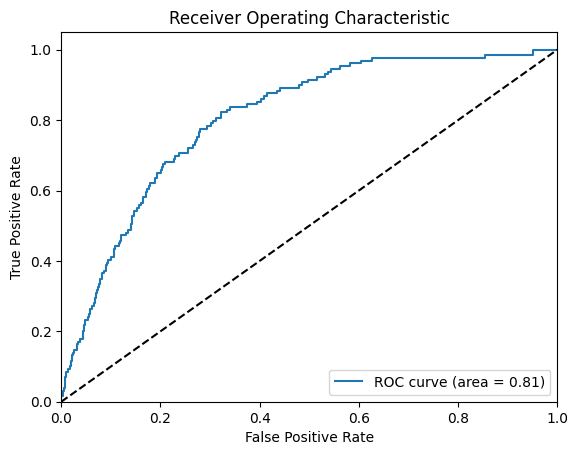

PR AUC: 0.17328819938734588


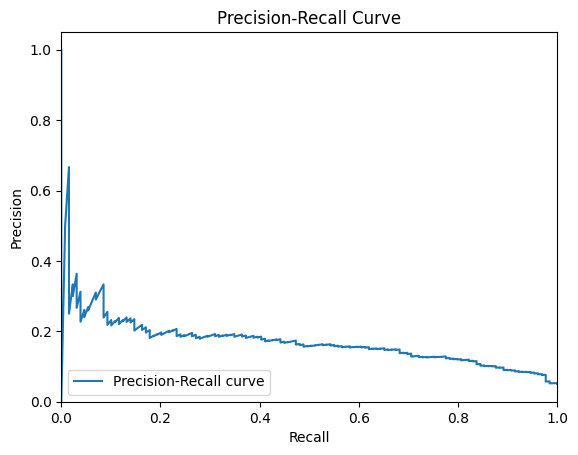

 85%|████████▍ | 11/13 [00:23<00:03,  1.85s/it]


Confusion Matrix:
 [[2420    6]
 [ 127    2]]


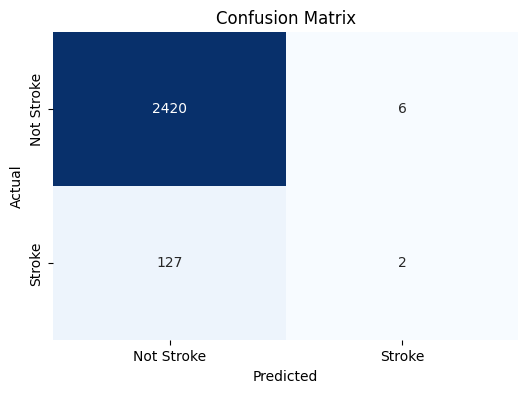


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97      2426
      Stroke       0.25      0.02      0.03       129

    accuracy                           0.95      2555
   macro avg       0.60      0.51      0.50      2555
weighted avg       0.91      0.95      0.93      2555

ROC-AUC: 0.8036356780868754


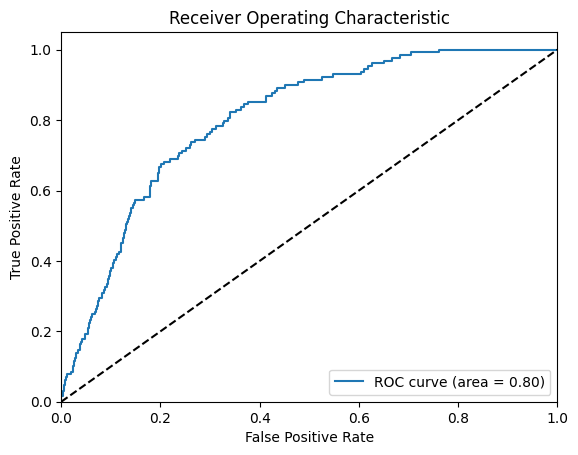

PR AUC: 0.1699285179789252


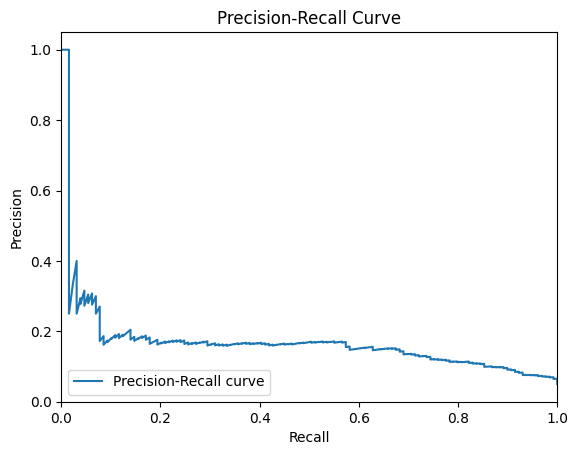

 92%|█████████▏| 12/13 [00:26<00:02,  2.29s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 120, number of negative: 2435
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000868 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 630
[LightGBM] [Info] Number of data points in the train set: 2555, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.046967 -> initscore=-3.010210
[LightGBM] [Info] Start training from score -3.010210

Confusion Matrix:
 [[2410   16]
 [ 124    5]]


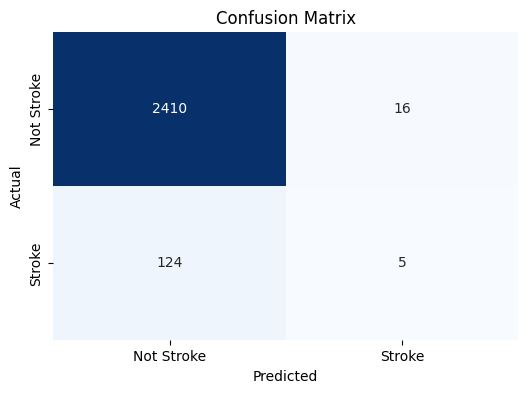


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.24      0.04      0.07       129

    accuracy                           0.95      2555
   macro avg       0.59      0.52      0.52      2555
weighted avg       0.92      0.95      0.93      2555

ROC-AUC: 0.8158802891159722


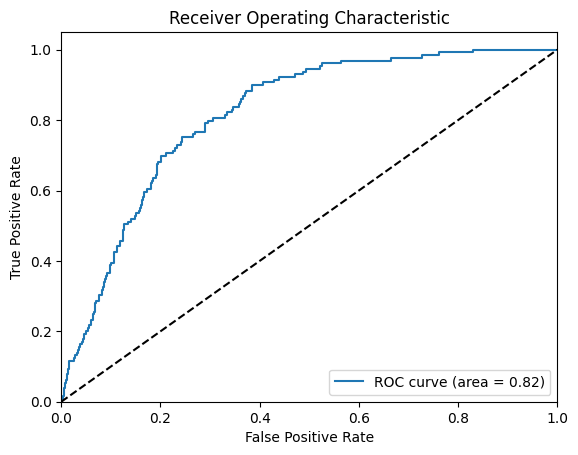

PR AUC: 0.16057948172805148


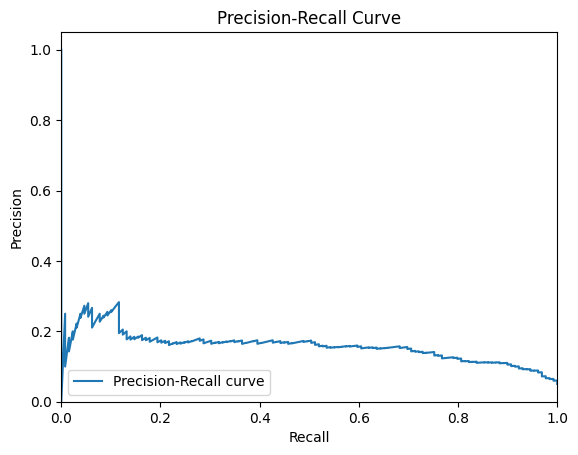

100%|██████████| 13/13 [00:27<00:00,  2.12s/it]


In [43]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:46:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[2412   14]
 [ 124    5]]


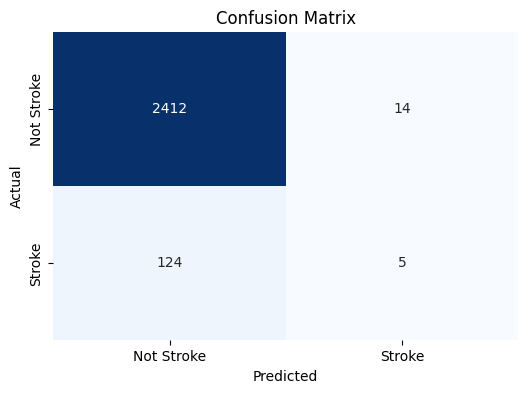


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.26      0.04      0.07       129

    accuracy                           0.95      2555
   macro avg       0.61      0.52      0.52      2555
weighted avg       0.92      0.95      0.93      2555

ROC-AUC: 0.8391648612895186


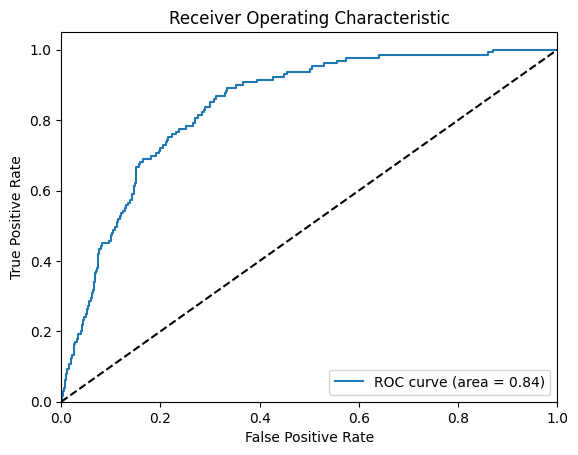

PR AUC: 0.1946501416173183


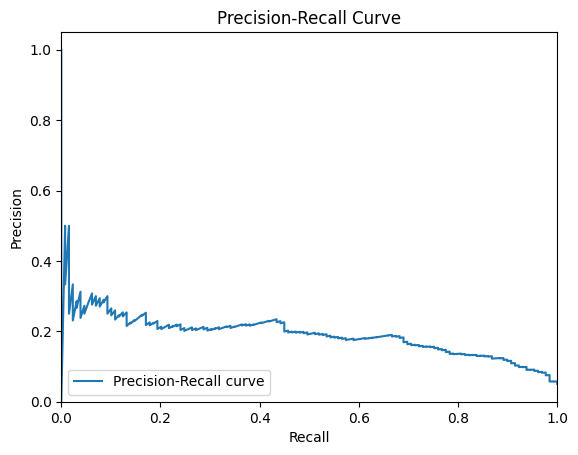

In [44]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:46:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[2395   31]
 [ 128    1]]


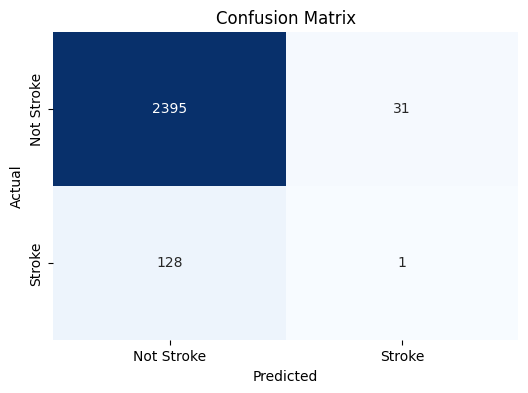


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97      2426
      Stroke       0.03      0.01      0.01       129

    accuracy                           0.94      2555
   macro avg       0.49      0.50      0.49      2555
weighted avg       0.90      0.94      0.92      2555

ROC-AUC: 0.7709471679543959


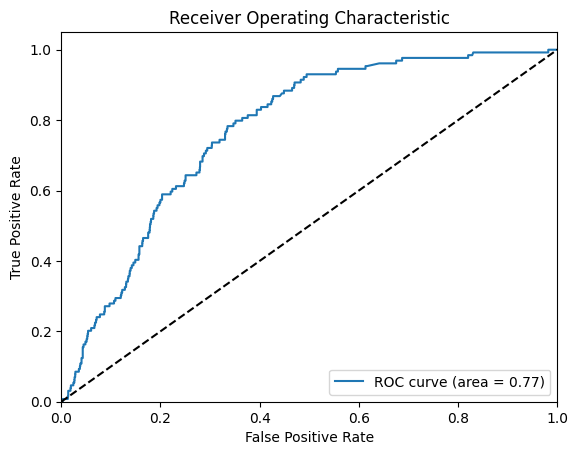

PR AUC: 0.1184758129507475


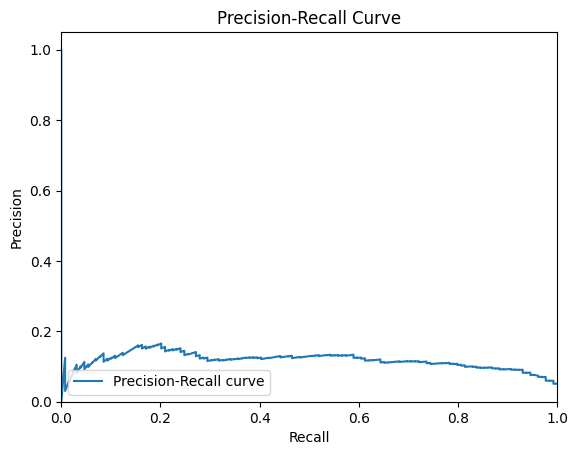

In [45]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [46]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [47]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,0.914677,1.000000,0.175182,1.000000,0.186047,1.000000,0.180451,1.000000,0.569734,0.569734,0.073688
Naive Bayes,0.362818,0.362035,0.068650,0.072365,1.000000,0.984496,0.128480,0.134820,0.665708,0.656716,0.812688,0.189811
XGBoost,1.000000,0.945205,1.000000,0.310345,1.000000,0.069767,1.000000,0.113924,1.000000,0.530762,0.805783,0.173288
Hist Gradient Boosting,1.000000,0.947945,1.000000,0.400000,1.000000,0.062016,1.000000,0.107383,1.000000,0.528535,0.814580,0.182724
Voting Classifier,1.000000,0.945988,1.000000,0.263158,1.000000,0.038760,1.000000,0.067568,1.000000,0.516494,0.839165,0.194650
LightGBM,1.000000,0.945205,1.000000,0.238095,1.000000,0.038760,1.000000,0.066667,1.000000,0.516082,0.815880,0.160579
Extra Trees,1.000000,0.944031,1.000000,0.208333,1.000000,0.038760,1.000000,0.065359,1.000000,0.515464,0.724969,0.111256
KNN,0.954990,0.944814,0.777778,0.200000,0.058333,0.031008,0.108527,0.053691,0.528756,0.512206,0.670837,0.100713
CatBoost,0.981213,0.947945,1.000000,0.250000,0.600000,0.015504,0.750000,0.029197,0.800000,0.506515,0.803636,0.169929
Logistic Regression,0.953033,0.949902,0.000000,1.000000,0.000000,0.007752,0.000000,0.015385,0.500000,0.503876,0.838101,0.247251


<Axes: >

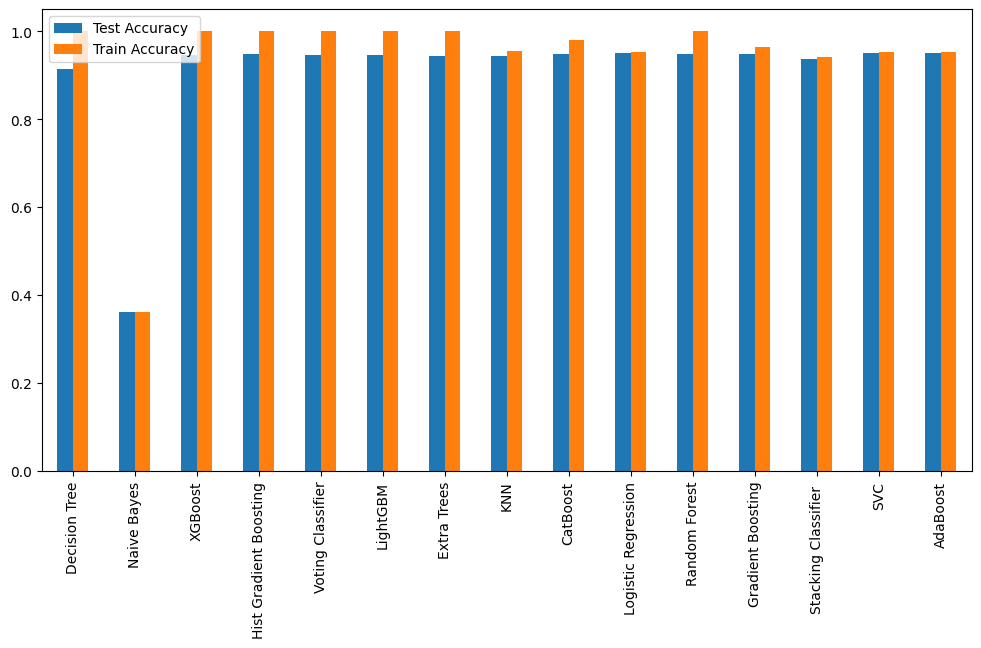

In [48]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

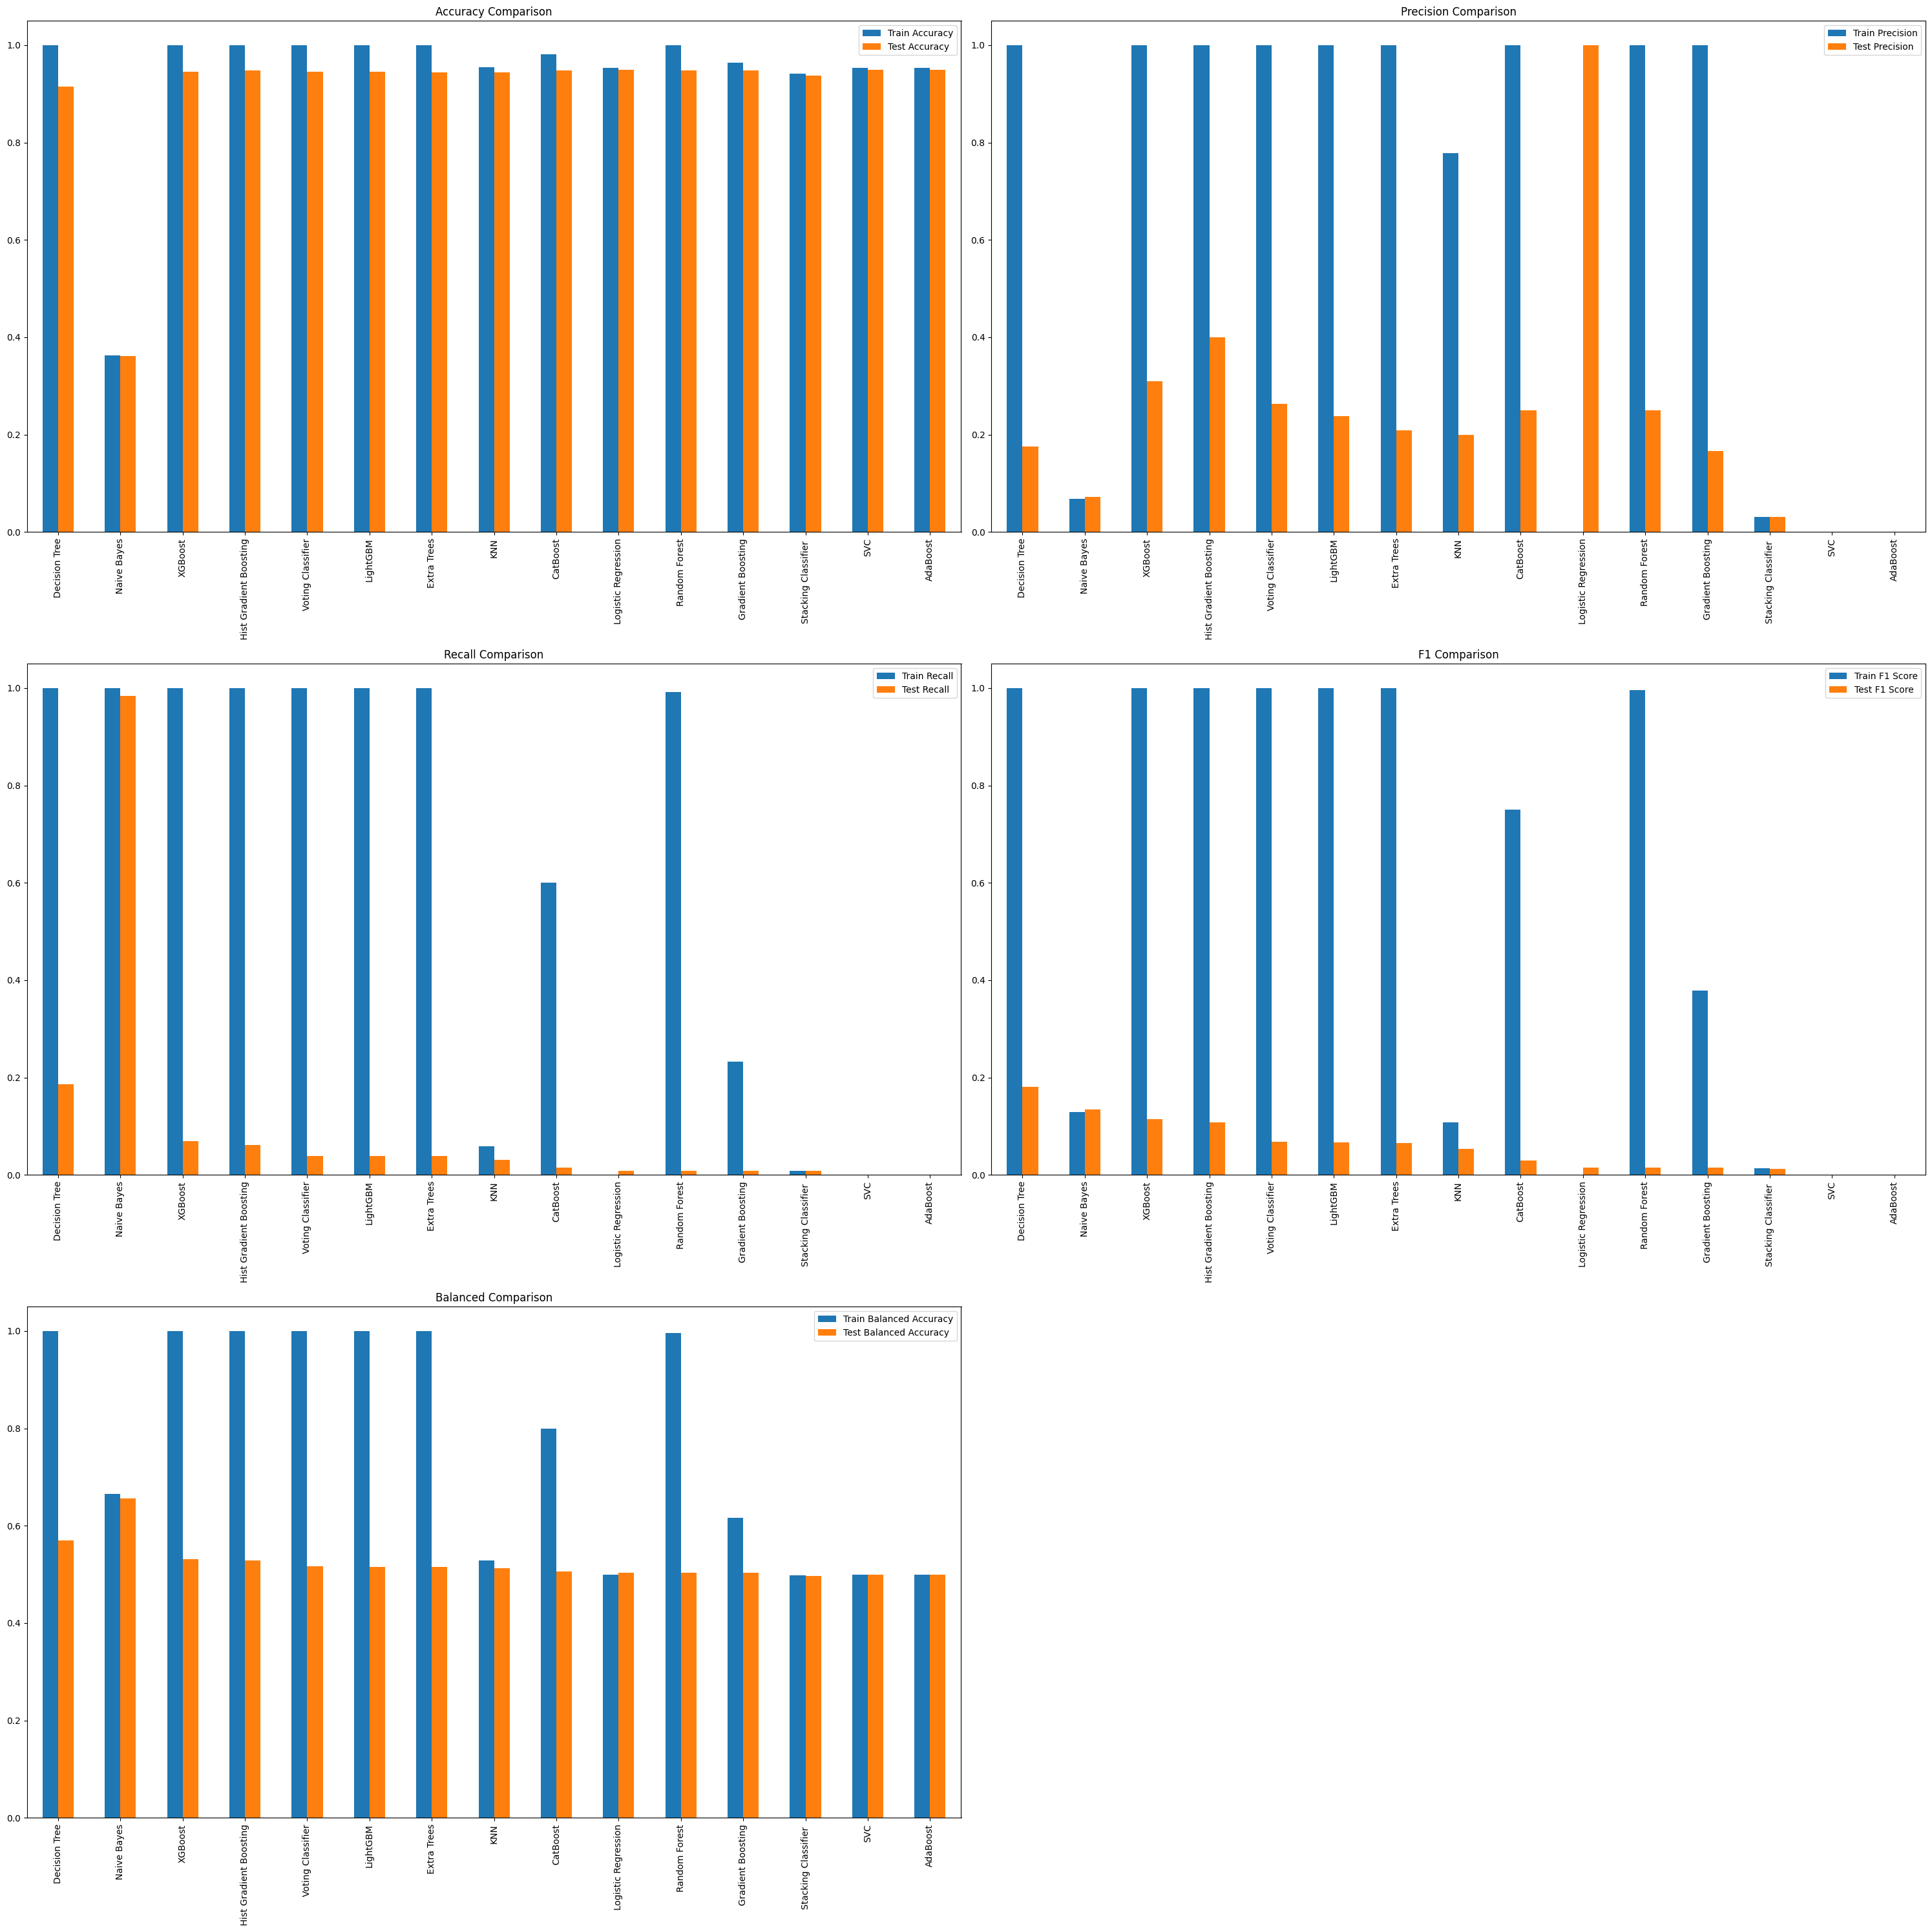

In [49]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()